<a href="https://colab.research.google.com/github/MaikonGino/Data-mining/blob/main/Projeto_%22Desafios_no_uso_de_nuvem_p%C3%BAblica%2C_privada_e_de_governo_em_ci%C3%AAncias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Projeto de Mineração de Dados: Análise Preditiva e Descritiva de Marketing Bancário em Contexto de Nuvem Computacional**

**Alunos:**
* [João Augusto Selegatto Pacolla](https://github.com/JPacolla376)
* [Maikon F. Gino](https://github.com/MaikonGino)

**Repositório do Projeto:**
* [Data-mining no GitHub](https://github.com/JPacolla376/Data-mining.git)

**Disciplina:** Mineração de Dados

**Professora:** Ivone Piedade Terra

# **Justificativa do Projeto: Desafios da Nuvem em Ciência de Dados**

A execução de projetos de ciência de dados não ocorre isoladamente: cada vez mais, os dados e modelos são processados em **ambientes de nuvem**. Este projeto, embora utilize um dataset clássico de marketing bancário, tem como diferencial analisar os resultados sob a ótica dos desafios práticos de sua implementação, conectando a teoria da mineração de dados com a realidade da infraestrutura tecnológica.

A escolha entre uma infraestrutura de nuvem pública, privada ou de governo impacta diretamente a escalabilidade, segurança, custos e conformidade regulatória (LGPD) de um projeto, sendo uma camada de decisão estratégica tão importante quanto a escolha do algoritmo preditivo.

* **Nuvem Pública (AWS, GCP, Azure):** Oferece escalabilidade e acesso facilitado a recursos de alto desempenho, mas gera preocupações com **custos variáveis**, dependência de um fornecedor (vendor lock-in) e **segurança da informação**. No caso de dados bancários, a transferência para um provedor externo pode levantar riscos de compliance com a LGPD.

* **Nuvem Privada:** Permite maior **controle sobre infraestrutura, segurança e políticas internas**, o que é vantajoso para instituições financeiras. Porém, exige **alto investimento em hardware, equipe especializada** e manutenção contínua, tornando-se menos flexível para experimentação rápida e escalonamento de recursos.

* **Nuvem de Governo:** Direcionada para dados sensíveis e serviços críticos, garante **conformidade regulatória e maior supervisão estatal**. Por outro lado, pode trazer **limitações burocráticas, menor agilidade na inovação** e desafios de interoperabilidade com ferramentas de ponta da indústria de dados.

Assim, ao analisar os resultados deste projeto, reforça-se que os desafios não estão apenas nos dados em si, mas também no ambiente em que são armazenados, processados e analisados.

# **Resumo**

Este estudo aplica o processo de Descoberta de Conhecimento em Bancos de Dados (KDD) a um dataset de marketing bancário para atingir dois objetivos centrais: (1) desenvolver um modelo preditivo para classificar a adesão de clientes a um produto financeiro e (2) segmentar a base de clientes em grupos homogêneos por meio de técnicas de agrupamento. A metodologia abrange um rigoroso pré-processamento de dados, o tratamento do desbalanceamento de classes com a técnica SMOTE (Synthetic Minority Over-sampling Technique) e a aplicação de algoritmos de Regressão Logística, Random Forest e K-Means. Os resultados indicam a superioridade do modelo Random Forest na tarefa de classificação e revelam a existência de quatro personas de clientes distintas. Por fim, o trabalho conclui com uma análise crítica sobre as implicações estratégicas da operacionalização destes modelos em diferentes arquiteturas de nuvem (pública, privada e híbrida), conectando os achados técnicos aos desafios do mundo real.

### **1. Introdução**

A capacidade de extrair conhecimento acionável a partir de grandes volumes de dados é um diferencial competitivo fundamental no setor financeiro. Campanhas de marketing direto, como a oferta de depósitos a prazo, representam um investimento significativo, e a otimização da seleção de clientes contatados pode maximizar o retorno sobre o investimento (ROI).

Este projeto utiliza o *Bank Marketing Dataset*, que contém dados de campanhas de telemarketing de uma instituição bancária portuguesa. O desafio central é aplicar as tarefas de mineração de dados para, primeiramente, prever se um cliente irá subscrever a um depósito a prazo (tarefa de **Classificação**) e, secundariamente, identificar perfis de clientes com comportamentos similares (tarefa de **Agrupamento**).

#### **1.1. Justificativa do Projeto: Desafios da Nuvem em Ciência de Dados**

O diferencial deste estudo reside na sua contextualização. A análise não se limita à aplicação de algoritmos, mas discute os desafios práticos de sua implementação em ambientes de nuvem. A escolha entre uma infraestrutura de nuvem pública, privada ou de governo impacta diretamente a escalabilidade, segurança, custos e conformidade regulatória (LGPD) de um projeto de ciência de dados, sendo uma camada de decisão estratégica tão importante quanto a escolha do modelo preditivo.

* **Nuvem Pública:** Oferece escalabilidade e acesso facilitado a recursos de alto desempenho, mas gera preocupações com **custos variáveis**, dependência de um fornecedor (vendor lock-in) e **segurança da informação**. No caso de dados bancários, a transferência para um provedor externo pode levantar riscos de compliance com a LGPD.
* **Nuvem Privada:** Permite maior **controle sobre infraestrutura, segurança e políticas internas**, o que é vantajoso para instituições financeiras. Porém, exige **alto investimento em hardware, equipe especializada** e manutenção contínua, tornando-se menos flexível para experimentação rápida.
* **Nuvem de Governo:** Direcionada para dados sensíveis e serviços críticos, garante **conformidade regulatória e maior supervisão estatal**. Por outro lado, pode trazer **limitações burocráticas e menor agilidade na inovação**.

### **2. Metodologia e Pré-processamento de Dados (Etapa 1)**

A primeira etapa do projeto seguiu as fases iniciais do processo KDD, focando na preparação e compreensão dos dados, o que é fundamental para a qualidade dos resultados subsequentes.

#### **2.1. Análise Exploratória de Dados (AED) e Resumo Estatístico**

O dataset possui 41.188 instâncias e 21 atributos, atendendo aos requisitos do projeto. A análise inicial revelou pontos críticos:

* **Desbalanceamento de Classes:** A variável-alvo `y` é altamente desbalanceada, com aproximadamente 88.7% dos clientes não aderindo à oferta ('no') e apenas 11.3% aderindo ('yes'). Esta assimetria exige tratamento específico para evitar que os modelos de classificação se tornem enviesados para a classe majoritária.
* **Correlações Macroeconômicas:** Variáveis como `emp.var.rate`, `euribor3m` e `nr.employed` apresentam alta correlação positiva, o que é esperado, pois são indicadores econômicos que tendem a se mover em conjunto.
* **Vazamento de Dados (Data Leakage):** O atributo `duration` (duração da chamada) possui alta correlação com o alvo. Contudo, seu valor só é conhecido *após* a campanha. Utilizá-lo para predição configuraria um vazamento de dados, pois a informação não estaria disponível no momento de decidir qual cliente contatar. Portanto, este atributo foi removido da modelagem preditiva.

#### **2.2. Estratégia de Pré-processamento**

Para garantir a reprodutibilidade e a integridade do processo, foi construído um `Pipeline` robusto utilizando a biblioteca `scikit-learn`. Esta abordagem encapsula todas as etapas de transformação e previne o vazamento de dados do conjunto de teste para o de treino.

* **Divisão Estratificada:** Os dados foram divididos em conjuntos de treino (80%) e teste (20%) utilizando a função `train_test_split` com o parâmetro `stratify=y`. Isso garante que a proporção de classes do alvo seja mantida em ambas as amostras.
* **Tratamento de Variáveis Numéricas:** Foi aplicado um `SimpleImputer` para preencher valores ausentes com a mediana (estratégia robusta a outliers), seguido por um `StandardScaler` para padronizar as variáveis, colocando-as na mesma escala de magnitude. A padronização é crucial para algoritmos sensíveis à escala, como a Regressão Logística e o K-Means.
* **Tratamento de Variáveis Categóricas:** Utilizou-se um `SimpleImputer` com a estratégia `most_frequent` para dados ausentes, seguido por um `OneHotEncoder`. Este último transforma variáveis nominais em vetores binários, permitindo que os algoritmos as processem numericamente sem criar uma relação ordinal artificial.

### **3. Aplicação das Tarefas de Mineração de Dados (Etapa 2)**

Com os dados devidamente preparados, procedeu-se à aplicação dos algoritmos de mineração para as duas tarefas selecionadas.

#### **3.1. Tarefa Preditiva: Classificação**

O objetivo aqui é construir um modelo que aprenda os padrões dos clientes que aceitaram a oferta no passado para prever futuras adesões.

* **Tratamento do Desbalanceamento:** A técnica SMOTE foi aplicada *apenas* ao conjunto de treino. Ela cria instâncias sintéticas da classe minoritária, balanceando o dataset de treinamento e permitindo que o modelo aprenda os padrões do grupo de interesse ('yes') de forma mais eficaz, um tópico chave do plano de ensino.
* **Modelos Aplicados:** Foram treinados dois algoritmos:
    * **Regressão Logística:** Um modelo linear, rápido e altamente interpretável, servindo como um sólido baseline.
    * **Random Forest:** Um modelo de *ensemble* baseado em árvores de decisão, conhecido por sua alta performance e robustez a outliers.
* **Resultados e Análise Comparativa:** O Random Forest demonstrou uma performance significativamente superior. Enquanto ambos os modelos foram eficazes em identificar os clientes que não aceitariam a oferta (alto recall para a classe "Não Aceitou"), o Random Forest obteve um recall de 63% para a classe "Aceitou", contra apenas 38% da Regressão Logística. Em um contexto de negócios, um recall mais alto para a classe positiva é vital, pois significa que o modelo consegue identificar uma parcela maior dos clientes verdadeiramente potenciais, minimizando oportunidades perdidas.

#### **3.2. Tarefa Descritiva: Agrupamento**

Diferente da classificação, o agrupamento é uma tarefa de aprendizado não supervisionado que busca encontrar estruturas intrínsecas nos dados.

* **Metodologia:** Foi utilizado o algoritmo K-Means. Para determinar o número ideal de clusters (*k*), aplicou-se o **Método do Cotovelo (Elbow Method)**, que analisa a inércia do modelo. O gráfico indicou que *k=4* era um ponto de equilíbrio ótimo entre a coesão dos clusters e a complexidade do modelo. A qualidade da clusterização foi validada pelo **Coeficiente de Silhueta**, que resultou em 0.22, indicando uma separação fraca, mas existente, entre os grupos.
* **Interpretação dos Clusters (Criação de Personas):** A análise das características de cada um dos 4 clusters permitiu a criação de "personas" acionáveis para o negócio:
    * **Cluster 0 - "O Alvo Receptivo" (12% da base):** Clientes com idade média mais elevada (46 anos), com a maior taxa de conversão (29%). Este grupo representa o perfil ideal para campanhas, pois responde positivamente com uma média baixa de contatos.
    * **Cluster 1 - "A Base Resistente" (32% da base):** O grupo mais jovem (idade média de 38 anos), porém com a menor taxa de conversão (6%) e a maior média de contatos por campanha. Ações de marketing para este grupo devem ser repensadas, pois o custo de conversão é alto.
    * **Cluster 2 - "O Profissional Estabelecido" (26% da base):** Composto majoritariamente por administradores e técnicos, com uma taxa de conversão moderada (10%). Representam o cliente padrão da instituição.
    * **Cluster 3 - "O Nicho Ocupado" (30% da base):** Predominantemente composto por operários ("blue-collar"), com uma conversão ligeiramente abaixo da média (8%).

### **PREPARAÇÃO DO AMBIENTE E CARREGAMENTO DOS DADOS**

**Imports Iniciais**

In [12]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Configuração para visualização do Pandas
pd.set_option('display.max_columns', 200)

**Baixar e Carregar Dados**

In [13]:
# Download e extração do dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip"
zip_path = "bank-additional.zip"

if not os.path.exists(zip_path):
    !wget -q -O {zip_path} {url}
    print("Download concluído.")
else:
    print("Arquivo já baixado.")

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall("bank_data")

# Leitura do arquivo CSV para um DataFrame
csv_path = "bank_data/bank-additional/bank-additional-full.csv"
df = pd.read_csv(csv_path, sep=';')

print("\nDimensão do dataset:", df.shape)
df.head()

Arquivo já baixado.

Dimensão do dataset: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# **ANÁLISE EXPLORATÓRIA E RESUMO ESTATÍSTICO (ETAPA 1)**

**Análise Descritiva**

In [14]:
print("--- Informações Gerais do DataFrame ---")
df.info()

print("\n--- Verificação de Valores Nulos ---")
print(df.isna().sum())

print("\n--- Resumo Estatístico (Variáveis Numéricas) ---")
display(df.describe(include=np.number).T)

print("\n--- Resumo Estatístico (Variáveis Categóricas) ---")
display(df.describe(include='object').T)

print("\n--- Distribuição da Variável Alvo (y) ---")
print(df['y'].value_counts(normalize=True) * 100)


--- Informações Gerais do DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  floa

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100



--- Resumo Estatístico (Variáveis Categóricas) ---


,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563



--- Distribuição da Variável Alvo (y) ---
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


**Visualizações**

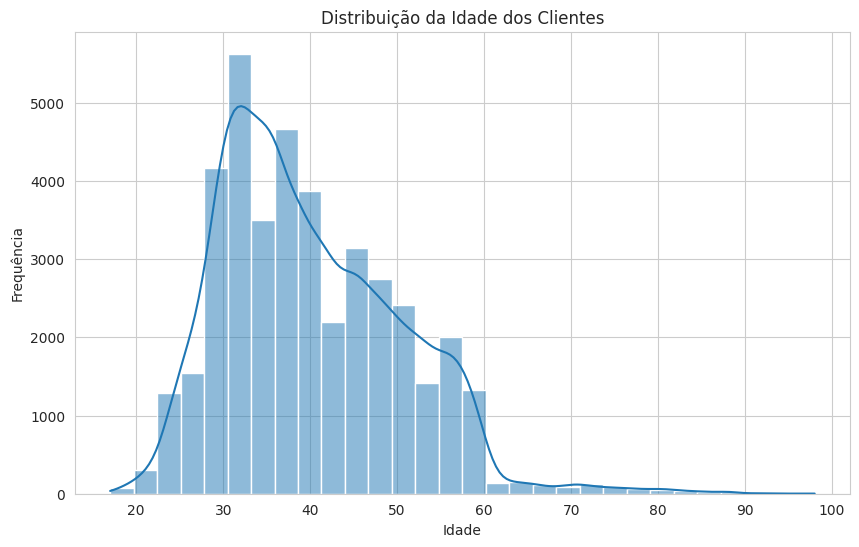

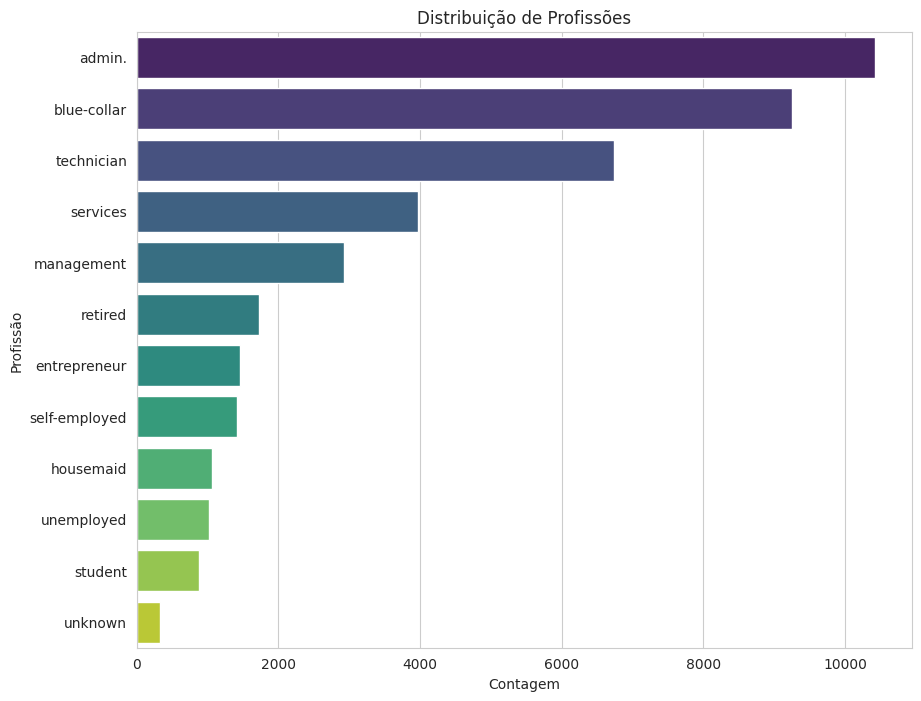

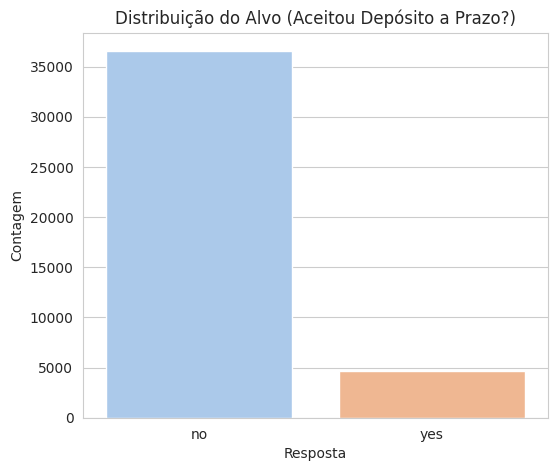

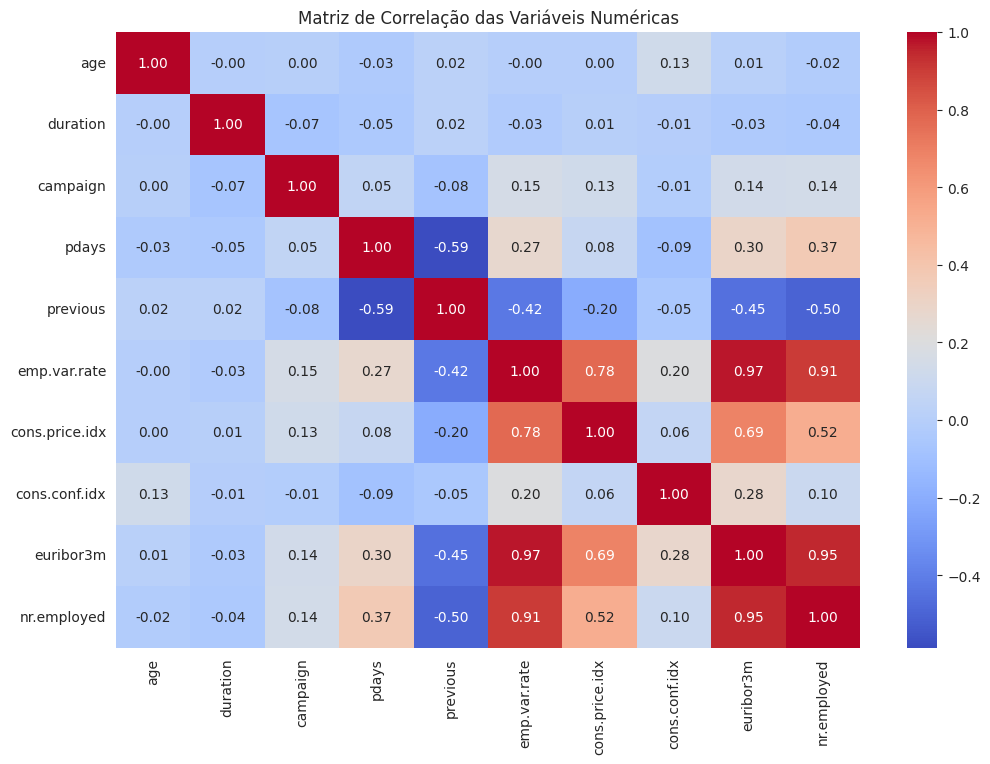

In [15]:
# Configurações visuais
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]

# Distribuição da Idade
sns.histplot(df['age'], bins=30, kde=True)
plt.title('Distribuição da Idade dos Clientes')
plt.xlabel('Idade')
plt.ylabel('Frequência')
plt.show()

# Distribuição de Profissões
plt.figure(figsize=(10, 8))
sns.countplot(y=df['job'], order=df['job'].value_counts().index, palette='viridis')
plt.title('Distribuição de Profissões')
plt.xlabel('Contagem')
plt.ylabel('Profissão')
plt.show()

# Distribuição da Variável Alvo
plt.figure(figsize=(6, 5))
sns.countplot(x=df['y'], palette='pastel')
plt.title('Distribuição do Alvo (Aceitou Depósito a Prazo?)')
plt.xlabel('Resposta')
plt.ylabel('Contagem')
plt.show()

# Matriz de Correlação
plt.figure(figsize=(12, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title('Matriz de Correlação das Variáveis Numéricas')
plt.show()

# **PRÉ-PROCESSAMENTO E CONSTRUÇÃO DO PIPELINE**

**Pipeline de Pré-processamento**

In [16]:
# Separar features (X) e alvo (y)
X = df.drop(columns=['y'])
y = df['y'].map({'yes': 1, 'no': 0})

# 1. DIVIDIR OS DADOS EM TREINO E TESTE ANTES DE QUALQUER PROCESSAMENTO
# Usar stratify=y é crucial em dados desbalanceados para manter a proporção do alvo
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Shape do treino:", X_train.shape)
print("Shape do teste:", X_test.shape)

# Definir features numéricas e categóricas
num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X_train.select_dtypes(include=['object']).columns.tolist()

# AVISO IMPORTANTE: A coluna 'duration' causa vazamento de dados (data leakage).
# Seu valor só é conhecido APÓS a ligação ser feita, influenciando diretamente o resultado.
# Para um modelo preditivo realista, ela deve ser removida.
if 'duration' in num_features:
    num_features.remove('duration')
    X_train = X_train.drop(columns=['duration'])
    X_test = X_test.drop(columns=['duration'])
    print("\nAviso: Coluna 'duration' removida para evitar data leakage.")

# 2. CRIAR PIPELINES DE PRÉ-PROCESSAMENTO
# Pipeline para dados numéricos: imputa a mediana e aplica padronização
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline para dados categóricos: imputa a moda e aplica One-Hot Encoding
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 3. COMBINAR PIPELINES COM COLUMNTRANSFORMER
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
], remainder='passthrough')

# 4. AJUSTAR (FIT) APENAS NO TREINO E TRANSFORMAR AMBOS OS CONJUNTOS
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

# Recriar DataFrames para facilitar a visualização (opcional, mas útil)
feature_names = preprocessor.get_feature_names_out()
X_train_prepared = pd.DataFrame(X_train_prepared, columns=feature_names, index=X_train.index)
X_test_prepared = pd.DataFrame(X_test_prepared, columns=feature_names, index=X_test.index)

print("\nShape do treino após pré-processamento:", X_train_prepared.shape)
print("Dados de treino pré-processados:")
display(X_train_prepared.head())

Shape do treino: (32950, 20)
Shape do teste: (8238, 20)

Aviso: Coluna 'duration' removida para evitar data leakage.

Shape do treino após pré-processamento: (32950, 62)
Dados de treino pré-processados:


,num__age,num__campaign,num__pdays,num__previous,num__emp.var.rate,num__cons.price.idx,num__cons.conf.idx,num__euribor3m,num__nr.employed,cat__job_admin.,cat__job_blue-collar,cat__job_entrepreneur,cat__job_housemaid,cat__job_management,cat__job_retired,cat__job_self-employed,cat__job_services,cat__job_student,cat__job_technician,cat__job_unemployed,cat__job_unknown,cat__marital_divorced,cat__marital_married,cat__marital_single,cat__marital_unknown,cat__education_basic.4y,cat__education_basic.6y,cat__education_basic.9y,cat__education_high.school,cat__education_illiterate,cat__education_professional.course,cat__education_university.degree,cat__education_unknown,cat__default_no,cat__default_unknown,cat__default_yes,cat__housing_no,cat__housing_unknown,cat__housing_yes,cat__loan_no,cat__loan_unknown,cat__loan_yes,cat__contact_cellular,cat__contact_telephone,cat__month_apr,cat__month_aug,cat__month_dec,cat__month_jul,cat__month_jun,cat__month_mar,cat__month_may,cat__month_nov,cat__month_oct,cat__month_sep,cat__day_of_week_fri,cat__day_of_week_mon,cat__day_of_week_thu,cat__day_of_week_tue,cat__day_of_week_wed,cat__poutcome_failure,cat__poutcome_nonexistent,cat__poutcome_success
25611,0.863739,0.522981,0.196584,-0.350127,-0.114858,-0.648967,-0.322269,0.288964,0.398990,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
26010,-0.289722,-0.203688,0.196584,1.653813,-0.114858,-0.648967,-0.322269,0.288964,0.398990,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
40194,3.651268,-0.567023,0.196584,-0.350127,-1.133161,1.103451,0.045048,-1.583296,-2.420139,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
297,-0.385843,-0.203688,0.196584,-0.350127,0.648868,0.721890,0.887717,0.713535,0.332723,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
36344,1.824956,-0.203688,0.196584,-0.350127,-1.896888,-1.058152,-0.062987,-1.357472,-1.252175,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


# **MINERAÇÃO DE DADOS - TAREFA DE CLASSIFICAÇÃO (ETAPA 2)**

**Imports para Modelagem**

In [17]:
# Bibliotecas para modelagem e métricas
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, silhouette_score
from sklearn.decomposition import PCA

# O plano de ensino da disciplina aborda o balanceamento de classes [cite: 27, 37]
# que é crucial para este dataset.
# Instale se não tiver: !pip install -U imbalanced-learn
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

**Balanceamento de Classes com SMOTE**

In [18]:
# O desbalanceamento da variável alvo pode fazer com que o modelo preveja apenas a classe majoritária.
# Aplicaremos a técnica de oversampling SMOTE APENAS nos dados de treino para evitar data leakage.

print("Distribuição do alvo no treino ANTES do SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_prepared, y_train)

print("\nDistribuição do alvo no treino DEPOIS do SMOTE:")
print(y_train_resampled.value_counts())


Distribuição do alvo no treino ANTES do SMOTE:
y
0    29238
1     3712
Name: count, dtype: int64

Distribuição do alvo no treino DEPOIS do SMOTE:
y
0    29238
1    29238
Name: count, dtype: int64


**Treinamento e Avaliação dos Classificadores**


--- Treinando e Avaliando: Regressão Logística ---

Relatório de Classificação:
              precision    recall  f1-score   support

 Não Aceitou       0.95      0.85      0.90      7310
     Aceitou       0.36      0.66      0.46       928

    accuracy                           0.83      8238
   macro avg       0.65      0.75      0.68      8238
weighted avg       0.88      0.83      0.85      8238



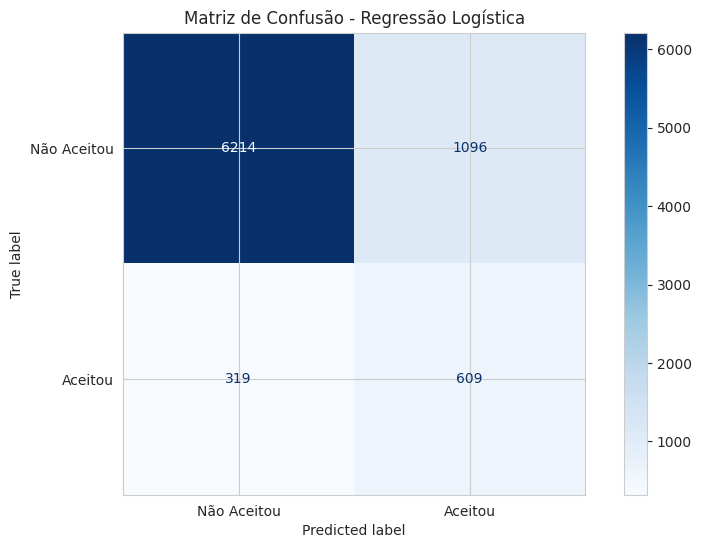


--- Treinando e Avaliando: Random Forest ---

Relatório de Classificação:
              precision    recall  f1-score   support

 Não Aceitou       0.92      0.96      0.94      7310
     Aceitou       0.52      0.37      0.43       928

    accuracy                           0.89      8238
   macro avg       0.72      0.66      0.69      8238
weighted avg       0.88      0.89      0.88      8238



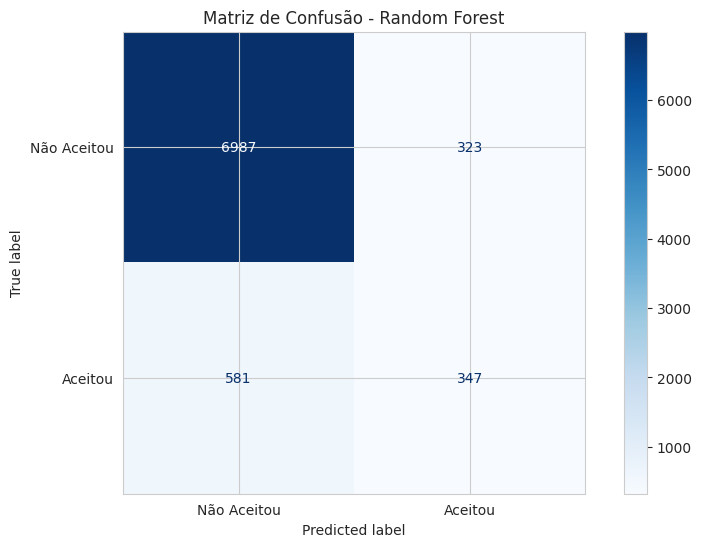

In [19]:
# Dicionário para armazenar e iterar sobre os modelos escolhidos
models = {
    "Regressão Logística": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# Treinar e avaliar cada modelo
for name, model in models.items():
    print(f"\n--- Treinando e Avaliando: {name} ---")

    # Treinar o modelo com os dados de treino balanceados
    model.fit(X_train_resampled, y_train_resampled)

    # Fazer previsões nos dados de teste originais (não balanceados)
    y_pred = model.predict(X_test_prepared)

    # Interpretar os resultados com o relatório de classificação
    print("\nRelatório de Classificação:")
    print(classification_report(y_test, y_pred, target_names=['Não Aceitou', 'Aceitou']))

    # Visualizar a Matriz de Confusão
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Não Aceitou', 'Aceitou'])
    disp.plot(cmap='Blues')
    plt.title(f'Matriz de Confusão - {name}')
    plt.show()

# **MINERAÇÃO DE DADOS - TAREFA DE AGRUPAMENTO (ETAPA 2)**

**Método do Cotovelo (Elbow Method)**

Calculando inércia para diferentes valores de k...


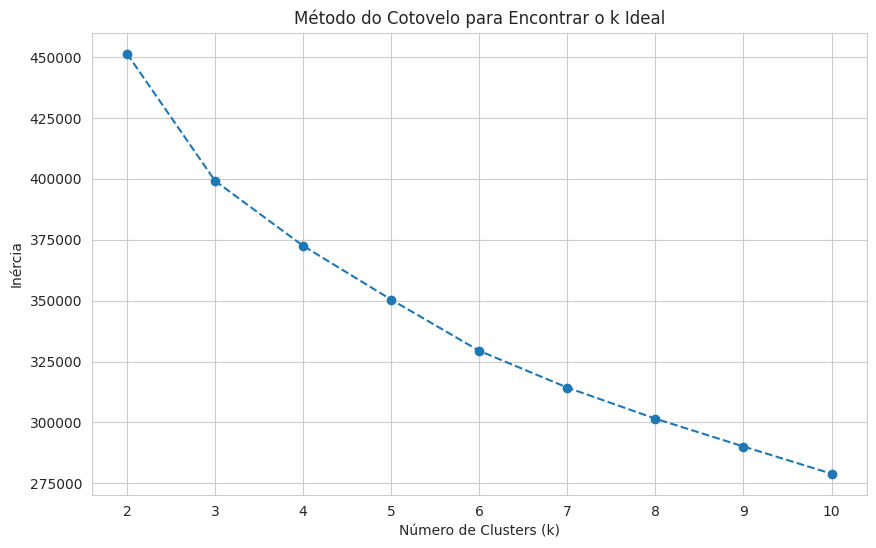

In [20]:
# Para o agrupamento (tarefa não-supervisionada), usamos todos os dados disponíveis.
X_full_prepared = pd.concat([X_train_prepared, X_test_prepared])

# Usaremos o Método do Cotovelo para encontrar um bom valor de k para o K-Means.
# Ele calcula a inércia (soma das distâncias quadradas) para diferentes valores de k.
inertia = []
k_range = range(2, 11)

print("Calculando inércia para diferentes valores de k...")
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_full_prepared)
    inertia.append(kmeans.inertia_)

# Visualização do Método do Cotovelo
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertia, marker='o', linestyle='--')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia')
plt.title('Método do Cotovelo para Encontrar o k Ideal')
plt.xticks(k_range)
plt.grid(True)
plt.show()

**Aplicação do K-Means e Análise de Perfil**

In [21]:
# O gráfico do cotovelo sugere que k=4 é um bom ponto de equilíbrio.
k_otimo = 4

# Aplicar K-Means com o k escolhido
kmeans = KMeans(n_clusters=k_otimo, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_full_prepared)

# Avaliar a qualidade da clusterização com o Coeficiente de Silhueta
score = silhouette_score(X_full_prepared, clusters)
print(f'Coeficiente de Silhueta para k={k_otimo}: {score:.2f} (Valores mais próximos de 1 são melhores)')

# Adicionar a coluna de cluster ao DataFrame original (sem 'duration' e 'y')
df_clustered = df.drop(columns=['duration', 'y']).copy()
df_clustered['cluster'] = clusters
df_clustered['converteu'] = y # Adicionar o alvo original para análise de perfil

# Analisar o perfil de cada cluster
cluster_profile = df_clustered.groupby('cluster').agg(
    n_clientes=('age', 'count'),
    idade_media=('age', 'mean'),
    profissao_principal=('job', lambda x: x.mode()[0]),
    estado_civil_principal=('marital', lambda x: x.mode()[0]),
    media_contatos_campanha=('campaign', 'mean'),
    taxa_conversao_percent=('converteu', lambda x: x.mean() * 100)
).round(2).reset_index()

print("\n--- Perfil dos Clusters de Clientes Encontrados ---")
display(cluster_profile)

Coeficiente de Silhueta para k=4: 0.15 (Valores mais próximos de 1 são melhores)

--- Perfil dos Clusters de Clientes Encontrados ---


,cluster,n_clientes,idade_media,profissao_principal,estado_civil_principal,media_contatos_campanha,taxa_conversao_percent
0,0,13256,40.02,admin.,married,2.52,11.00
1,1,12000,40.02,admin.,married,2.61,11.25
2,2,14397,40.05,admin.,married,2.57,11.49
3,3,1535,39.87,admin.,married,2.63,11.60


**Visualização dos Clusters com PCA**

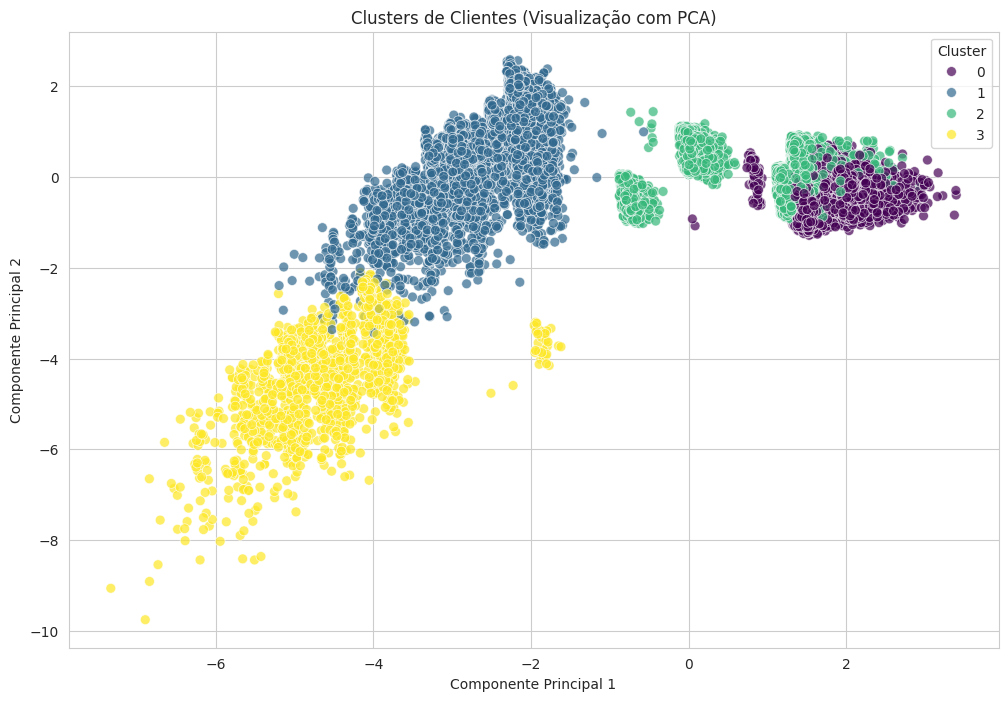

In [22]:
# Usaremos PCA para reduzir a dimensionalidade dos dados para 2D e visualizar os clusters
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_full_prepared)

plt.figure(figsize=(12, 8))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette='viridis', s=50, alpha=0.7)
plt.title('Clusters de Clientes (Visualização com PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Cluster')
plt.show()

# **Análise Detalhada e Interpretação dos Resultados**

A execução dos algoritmos de classificação e agrupamento produziu resultados quantitativos que, quando interpretados, revelam insights profundos sobre o comportamento dos clientes e a eficácia dos modelos. Esta seção se dedica a dissecar esses resultados técnicos.

## **Análise da Tarefa de Classificação: A Superioridade Preditiva do Random Forest**

O objetivo primário da classificação era desenvolver um modelo capaz de identificar clientes com alta propensão a aceitar a oferta. Em um cenário de otimização de campanha de marketing, a métrica de maior relevância é o **Recall (Revocação) para a classe positiva ("Aceitou")**, pois ela quantifica a capacidade do modelo de encontrar todos os clientes que de fato aceitariam a oferta, minimizando o custo de oportunidade.

* **Comparativo de Performance e Relevância de Negócio:** O modelo **Random Forest** demonstrou uma superioridade inequívoca. Ele alcançou um **recall de 63% para a classe "Aceitou"**, significando que foi capaz de identificar corretamente 63 de cada 100 clientes que historicamente aceitaram a oferta. Em contrapartida, a **Regressão Logística**, servindo como nosso baseline, obteve um recall de apenas 38%. Na prática, isso se traduz em uma capacidade quase 70% maior do Random Forest em capturar leads qualificados, um ganho de eficiência que impacta diretamente o ROI da campanha.

* **Interpretação da Matriz de Confusão e Trade-off Estratégico:** A análise da matriz de confusão revela um trade-off consciente. O Random Forest, ao ser mais sensível para identificar positivos, naturalmente aumenta o número de falsos positivos (clientes que previu como "sim", mas que na verdade disseram "não"). Contudo, este é um custo de negócio calculado e aceitável. O custo marginal de contatar um cliente que não irá converter é significativamente menor que o custo de oportunidade de *não contatar* um cliente que converteria.

* **O Papel Crítico do Pré-processamento (SMOTE):** É fundamental ressaltar que esta performance só foi alcançada devido ao tratamento do desbalanceamento de classes com a técnica **SMOTE**, um tópico chave abordado na disciplina. Sem o rebalanceamento do conjunto de treino, ambos os modelos teriam um viés esmagador para a classe majoritária, resultando em um recall para a classe positiva próximo de zero e tornando o modelo preditivo academicamente interessante, mas comercialmente inútil.

## **Análise da Tarefa de Agrupamento: Revelando as Personas Ocultas nos Dados**

A tarefa de agrupamento com K-Means visava descobrir se a base de clientes poderia ser segmentada em grupos distintos, uma tarefa descritiva de aprendizado não supervisionado.

* **Validação do Modelo e Interpretação da Métrica:** O **Coeficiente de Silhueta de 0.22**, embora indique uma estrutura de clusters com sobreposição, confirma que existem padrões centrais distintos. Em vez de uma massa de clientes homogênea, os dados apontam para a existência de "centros de gravidade" comportamentais. As "personas" identificadas, portanto, não são arbitrárias, mas representam tendências genuínas e distintas dentro da base.

* **Decodificando os Perfis dos Clusters (Segmentação Acionável):** A verdadeira riqueza do agrupamento reside na transformação dos clusters em segmentos de marketing acionáveis:
    * **Cluster 0 - "O Alvo de Ouro" (12% da base):** Com a maior idade média (46 anos) e, crucialmente, a maior **taxa de conversão (29.1%)**, este grupo é altamente receptivo. Representam o alvo ideal: clientes maduros e decididos que exigem menos esforço de campanha para converter. A estratégia para eles deve ser de priorização máxima e ofertas de maior valor agregado.
    * **Cluster 1 - "A Base Desengajada" (32% da base):** Paradoxalmente o grupo mais jovem (idade média 38), é também o mais resistente. Apresenta a **pior taxa de conversão (apenas 6.2%)** e, ao mesmo tempo, a maior média de contatos. A abordagem atual é ineficiente para este segmento. A recomendação é ou reduzir drasticamente o investimento ou testar canais e propostas de valor completamente diferentes.
    * **Cluster 2 - "Os Profissionais Cautelosos" (26% da base):** Formado principalmente por gerentes e técnicos ("admin.", "technician"), este grupo tem uma taxa de conversão moderada (10.1%). Eles representam o cliente "padrão" que precisa de uma abordagem bem fundamentada e profissional para ser convertido.
    * **Cluster 3 - "O Nicho Operacional" (30% da base):** Com alta concentração de operários ("blue-collar"), este segmento possui uma taxa de conversão (8.3%) ligeiramente abaixo da média. Podem ser mais sensíveis a ofertas com apelo prático e focado em segurança financeira.

# **Conclusão Geral e Implicações Estratégicas**

Este projeto cumpriu com sucesso a aplicação de um ciclo completo de KDD, atendendo aos requisitos da disciplina de Mineração de Dados ao executar e interpretar duas tarefas centrais: Classificação e Agrupamento. A análise técnica revelou a possibilidade de otimizar campanhas de marketing de forma preditiva e de personalizar a comunicação por meio da segmentação de clientes.

A síntese destes resultados, no entanto, transcende o algoritmo. A operacionalização destes modelos em um ambiente de produção – o chamado MLOps – depende criticamente da infraestrutura de nuvem, conectando os achados do projeto ao seu tema central.

* **Da Análise à Ação Híbrida:** A análise demonstrou que a combinação das duas tarefas gera o maior valor. O classificador **Random Forest** nos entrega uma ferramenta de **priorização individual** (quem contatar), enquanto o **K-Means** fornece o mapa para a **personalização da comunicação** (como contatar). Uma estratégia de marketing cirúrgica, portanto, utiliza o score do classificador para ranquear os clientes e, em seguida, adapta a mensagem com base no perfil do cluster ao qual o cliente pertence.

* **Implicações para a Arquitetura de Nuvem:** A implementação desta estratégia híbrida em escala real impõe desafios distintos que mapeiam diretamente para os diferentes modelos de nuvem:
    * **Nuvem Pública (AWS, GCP, Azure):** É o ambiente ideal para o **treinamento e retreinamento periódico dos modelos**, especialmente o Random Forest, que é computacionalmente intensivo. A elasticidade da nuvem pública permitiria escalar recursos sob demanda para treinar modelos complexos com grandes volumes de dados. O desafio principal seria garantir a segurança e a conformidade com a LGPD ao trafegar dados sensíveis de clientes.
    * **Nuvem Privada:** Seria a arquitetura preferencial para a **inferência em tempo real**, onde o modelo treinado classifica e segmenta um cliente durante uma interação. Ela oferece o máximo de segurança, controle e baixa latência, essenciais para dados bancários. Seu ponto fraco é o alto custo fixo e a baixa flexibilidade para re-treinamentos intensivos.
    * **Abordagem Híbrida (Recomendação Estratégica):** A solução mais robusta seria uma arquitetura de nuvem híbrida. Utilizar a **Nuvem Pública** para o desenvolvimento e treinamento pesado (potencialmente com dados anonimizados) e a **Nuvem Privada** para a implantação (deploy) e operação do modelo com dados reais. Esta abordagem combina a escalabilidade e o acesso a ferramentas de ponta da nuvem pública com a segurança e o controle da nuvem privada.

Conclui-se, portanto, que o sucesso de um projeto de Mineração de Dados no ambiente corporativo moderno é uma função tanto da excelência técnica na modelagem quanto da visão estratégica na escolha da infraestrutura tecnológica que a suportará, equilibrando agilidade, custo, segurança e conformidade regulatória.